In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [2]:
def roundHalf(value):
    return np.round(value * 2) / 2

class Piece:

    rotation = 1
    flipped = False
    placed = False
    pattern = None # This will be a string to help define the patterns of connections

    def __init__(self, fileLocation=None):
        self.fileLocation = fileLocation
        self.name = os.path.splitext(os.path.basename(fileLocation))[0]    
        self.createPiece(fileLocation)
    
    def calculateCenter(self):
        self.data['center_x'] = (self.data['v1_x'] + self.data['v2_x'] + self.data['v3_x']) / 3
        self.data['center_y'] = (self.data['v1_y'] + self.data['v2_y'] + self.data['v3_y']) / 3

    def createPiece(self, fileLocation):
        df = pd.read_csv(fileLocation)
        df = df.set_index("triangle_id")
        self.data = df
        self.calculateCenter()

    def rotateForwards(self):
        # Rotate All Three Vertices.
        for vertex in range(1,4):
            # We have to update the axis individually and the calculations are based on the original.
            x = self.data['v'+str(vertex)+'_x']
            y = self.data['v'+str(vertex)+'_y']
            self.data['v'+str(vertex)+'_x'] = roundHalf(x*np.cos(np.pi/3) - y*np.sin(np.pi/3))
            self.data['v'+str(vertex)+'_y'] = roundHalf(y*np.cos(np.pi/3) + x*np.sin(np.pi/3))
        self.rotation += 1
        self.calculateCenter()

    def rotateBackwords(self):
        # Rotate All Three Vertices.
        for vertex in range(1,4):
            # We have to update the axis individually and the calculations are based on the original.
            x = self.data['v'+str(vertex)+'_x']
            y = self.data['v'+str(vertex)+'_y']
            self.data['v'+str(vertex)+'_x'] = roundHalf(x*np.cos((-1*np.pi)/3) - y*np.sin((-1*np.pi)/3))
            self.data['v'+str(vertex)+'_y'] = roundHalf(y*np.cos((-1*np.pi)/3) + x*np.sin((-1*np.pi)/3))
        self.rotation += 1
        self.calculateCenter()

    def flipPiece(self):
        for vertex in range(1,4):
            self.data['v'+str(vertex)+'_x'] = -1 * self.data['v'+str(vertex)+'_x']
        self.flipped = not self.flipped
        self.calculateCenter()


In [15]:
def rollDice(board):
    rand1 = np.random.choice([12, 13, 23, 24, 32, 33, 41, 42])
    board.loc[rand1, "piece"] = "obstacle"
    rand2 = np.random.choice([2, 4, 7, 8, 9, 11, 16, 17])
    board.loc[rand2, "piece"] = "obstacle"
    rand3 = np.random.choice([25, 26, 36, 37, 38, 40, 45, 47])
    board.loc[rand3, "piece"] = "obstacle"
    rand4 = np.random.choice([10,27,31])
    board.loc[rand4, "piece"] = "obstacle"
    rand5 = np.random.choice([18, 22, 39])
    board.loc[rand5, "piece"] = "obstacle"
    rand6 = np.random.choice([1, 5, 15, 34, 44, 48])
    board.loc[rand6, "piece"] = "obstacle"
    rand7 = np.random.choice([19, 20, 21, 28, 29, 30])
    board.loc[rand7, "piece"] = "obstacle"
    print(f"The Dice Rolls are {rand1}, {rand2}, {rand3}, {rand4}, {rand5}, {rand6}, {rand7}")
    return board

def setupGame():
    # Create Board
    board = pd.read_csv("Resources3/Board.csv")
    board['center_x'] = (board['v1_x'] + board['v2_x'] + board['v3_x']) / 3
    board['center_y'] = (board['v1_y'] + board['v2_y'] + board['v3_y']) / 3
    board["piece"] = None
    board = board.set_index('triangle_id')
    # Place Obstacles
    board = rollDice(board)
    # Create Pieces
    folderPath = "Resources3/GamePieces/"
    pieces = {}
    for fileName in os.listdir(folderPath):
        filePath = os.path.join(folderPath, fileName)
        if os.path.isfile(filePath):
            pieces[fileName] = Piece(filePath)
    return board, pieces

def isSolved(board):
    return board["piece"].isna().count() > 0

def createFakePiece(vertex, piece):
    return pd.DataFrame({
        'v1_x': piece.data['v1_x'] + vertex[0],
        'v1_y': piece.data['v1_y'] + vertex[1],
        'v2_x': piece.data['v2_x'] + vertex[0],
        'v2_y': piece.data['v2_y'] + vertex[1],
        'v3_x': piece.data['v3_x'] + vertex[0],
        'v3_y': piece.data['v3_y'] + vertex[1]
    })

def placeIfValid(board, vertex, piece):
    # Calculate the Loactions of each Piece within the Board.
    fakePiece = createFakePiece(vertex, piece)
    # Calculate the Centers.
    fakePiece['center_x'] = (fakePiece['v1_x'] + fakePiece['v2_x'] + fakePiece['v3_x']) / 3
    fakePiece['center_y'] = (fakePiece['v1_y'] + fakePiece['v2_y'] + fakePiece['v3_y']) / 3
    # Are the Centers Open?
    triangles = board[board[['center_x', 'center_y']].apply(tuple, axis=1).isin(fakePiece[['center_x', 'center_y']].apply(tuple, axis=1))]
    if triangles[triangles['piece'].notnull()]['piece'].count() == 0:
        # If all spaces are open, place the piece.
        board.loc[triangles.index, 'piece'] = piece.name
        return board, True
    return board, False

def removePiece(board, piece):
    board[board['piece'] == piece.name, 'piece'] = None
    return None
    
def getBoardIndices(board):
    return pd.concat([
        board[['v1_x', 'v1_y']].apply(tuple, axis=1),
        board[['v2_x', 'v2_y']].apply(tuple, axis=1),
        board[['v3_x', 'v3_y']].apply(tuple, axis=1)
    ]).value_counts().index.values

def reorderPieces(pieces):
    return [pieces["DarkGreen5.csv"], pieces["Lavender5.csv"], pieces["LightGreen5.csv"], pieces["Red5.csv"], 
            pieces["Purple4.csv"], pieces["Orange4.csv"], pieces["Pink4.csv"], pieces["Blue3_1.csv"], pieces["Blue3_2.csv"], pieces["Yellow2.csv"], pieces["DarkBlue1.csv"]]

In [19]:
def solvePuzzle(board, indices, pieces):
    """ 
    Recursive Function that uses the board and available pieces as it's input
    In each call it takes a piece and brute force tries it at every triangle. Then rotates it. 
    If it ever succeeds it calls itself with 1 less piece. If it fails it returns itself witht the piece
    still available, then it continues the previous pieces brute force.
    """
    for piece in pieces:
        if not piece.placed:
            break
    if piece.placed:
        if isSolved(board):
            return board, pieces, True
        return board, pieces, False
    for indx in range(indices.size):
        board, placed = placeIfValid(board, indices[indx], piece)
        if placed:
            piece.placed = True
            board, pieces, solved = solvePuzzle(board, indices, pieces)
            if solved:
                return board, pieces, solved
            removePiece(board, piece)
            piece.placed = False
    piece.rotateForwards()
    if piece.name == "LightGreen5": print("Rotated ", piece.rotation)
    if piece.rotation <= 6:
        board, pieces, solved = solvePuzzle(board, indices, pieces)
        if solved:
            return board, pieces, solved
    piece.rotateBackwords()
    if not piece.flipped:
        piece.flipPiece()
        board, pieces, solved = solvePuzzle(board, indices, pieces)
        if solved:
            return board, pieces, solved
        piece.flipPiece()
    return board, pieces, False

In [21]:
board, pieces = setupGame()
pieces = reorderPieces(pieces)
indices = getBoardIndices(board)
solvedBoard, pieces, solved = solvePuzzle(board, indices, pieces)

The Dice Rolls are 33, 16, 26, 27, 39, 5, 19


In [22]:
solvedBoard

,v1_x,v1_y,v2_x,v2_y,v3_x,v3_y,center_x,center_y,piece
triangle_id,,,,,,,,,
1,0.0,4,-0.5,3,0.5,3,0.0,3.333333,Pink4
2,0.0,2,-1.0,2,-0.5,3,-0.5,2.333333,DarkGreen5
3,-0.5,3,0.5,3,0.0,2,0.0,2.666667,DarkGreen5
4,0.0,2,0.5,3,1.0,2,0.5,2.333333,DarkGreen5
5,-3.0,2,-2.5,1,-2.0,2,-2.5,1.666667,obstacle
6,-2.0,2,-2.5,1,-1.5,1,-2.0,1.333333,Orange4
7,-1.0,2,-2.0,2,-1.5,1,-1.5,1.666667,Orange4
8,-1.5,1,-1.0,2,-0.5,1,-1.0,1.333333,Orange4
9,0.0,2,-1.0,2,-0.5,1,-0.5,1.666667,DarkGreen5


<function matplotlib.pyplot.show(close=None, block=None)>

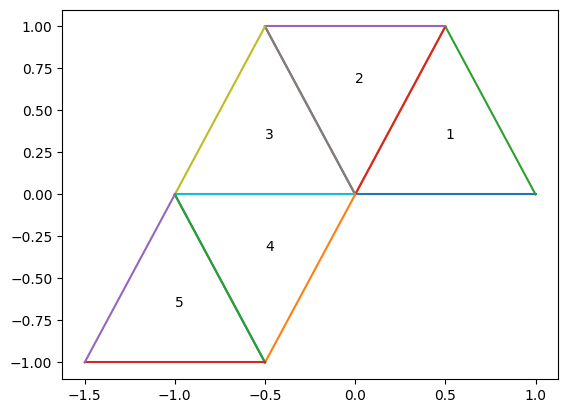

In [ ]:
# Plot the Board
fig, ax = plt.subplots()
idx = 5
for triangle in board.index:
    ax.plot(
        [board.loc[triangle, "v1_x"], board.loc[triangle, "v2_x"]],
        [ board.loc[triangle, "v1_y"],  board.loc[triangle, "v2_y"]]
    )
    ax.plot(
        [board.loc[triangle, "v2_x"], board.loc[triangle, "v3_x"]],
        [board.loc[triangle, "v2_y"], board.loc[triangle, "v3_y"]]
    )
    ax.plot(
        [board.loc[triangle, "v1_x"], board.loc[triangle, "v3_x"]],
        [board.loc[triangle, "v1_y"], board.loc[triangle, "v3_y"]]
    )
    ax.annotate(board.loc[triangle, "piece"], (board.loc[triangle, "center_x"], board.loc[triangle, "center_y"]))
plt.show

In [202]:
pd.concat([
        board[['v1_x', 'v1_y']].apply(tuple, axis=1),
        board[['v2_x', 'v2_y']].apply(tuple, axis=1),
        board[['v3_x', 'v3_y']].apply(tuple, axis=1)
    ]).value_counts().index.values

(0.0, 2.0)